<a href="https://colab.research.google.com/github/dzikrilazizhakim/Semester-5/blob/main/data_science_praktikum_dzikril_aziz_hakim_sesi_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

In [4]:
df = pd.read_csv('download')
df.head()

,ID_Transaksi,Warna_Tombol,Metode_Bayar,Waktu_Akses_Menit,Nominal_Transaksi
0,1,Biru,E-Wallet,5.2,150000
1,2,Hijau,Transfer Bank,12.5,250000
2,3,Biru,Kartu Kredit,3.1,350000
3,4,Hijau,E-Wallet,8.0,175000
4,5,Biru,E-Wallet,4.5,120000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   ID_Transaksi       20 non-null     int64  
 1   Warna_Tombol       20 non-null     object 
 2   Metode_Bayar       20 non-null     object 
 3   Waktu_Akses_Menit  20 non-null     float64
 4   Nominal_Transaksi  20 non-null     int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 932.0+ bytes


In [6]:
biru = df[df['Warna_Tombol'] == 'Biru']['Nominal_Transaksi']
hijau = df[df['Warna_Tombol'] == 'Hijau']['Nominal_Transaksi']

print("Rata-rata Biru:", biru.mean())
print("Rata-rata Hijau:", hijau.mean())

Rata-rata Biru: 205000.0
Rata-rata Hijau: 258000.0


In [7]:
hasil_ttest = stats.ttest_ind(biru, hijau)

print("T-Statistic:", hasil_ttest.statistic)
print("P-Value:", hasil_ttest.pvalue)

T-Statistic: -1.3226598599988706
P-Value: 0.202508039672407


In [8]:
ewallet = df[df['Metode_Bayar'] == 'E-Wallet']['Nominal_Transaksi']
transfer = df[df['Metode_Bayar'] == 'Transfer Bank']['Nominal_Transaksi']
kartu = df[df['Metode_Bayar'] == 'Kartu Kredit']['Nominal_Transaksi']

print("Rata-rata E-Wallet:", ewallet.mean())
print("Rata-rata Transfer Bank:", transfer.mean())
print("Rata-rata Kartu Kredit:", kartu.mean())

Rata-rata E-Wallet: 149285.7142857143
Rata-rata Transfer Bank: 207857.14285714287
Rata-rata Kartu Kredit: 355000.0


In [9]:
hasil_anova = stats.f_oneway(ewallet, transfer, kartu)

print("F-Statistic:", hasil_anova.statistic)
print("P-Value:", hasil_anova.pvalue)

F-Statistic: 76.72152213188804
P-Value: 3.0930855395370006e-09


In [10]:
hasil_korelasi = stats.pearsonr(
    df['Waktu_Akses_Menit'],
    df['Nominal_Transaksi']
)

print("Nilai Korelasi:", hasil_korelasi.statistic)
print("P-Value:", hasil_korelasi.pvalue)

Nilai Korelasi: 0.5555724975276234
P-Value: 0.010983593554484866


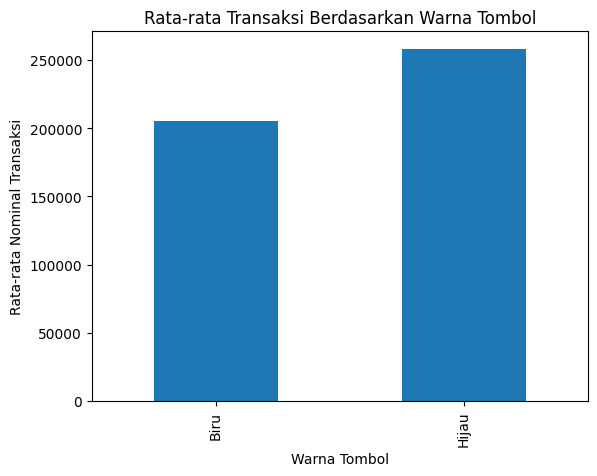

In [11]:
df.groupby('Warna_Tombol')['Nominal_Transaksi'].mean().plot(kind='bar')

plt.title('Rata-rata Transaksi Berdasarkan Warna Tombol')
plt.xlabel('Warna Tombol')
plt.ylabel('Rata-rata Nominal Transaksi')
plt.show()

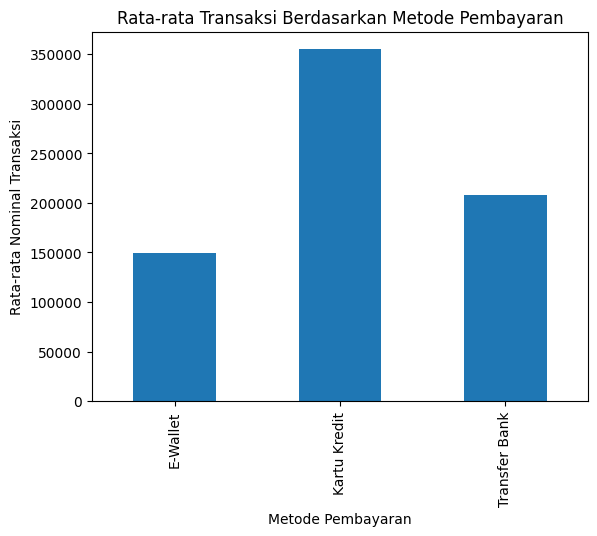

In [12]:
df.groupby('Metode_Bayar')['Nominal_Transaksi'].mean().plot(kind='bar')

plt.title('Rata-rata Transaksi Berdasarkan Metode Pembayaran')
plt.xlabel('Metode Pembayaran')
plt.ylabel('Rata-rata Nominal Transaksi')
plt.show()

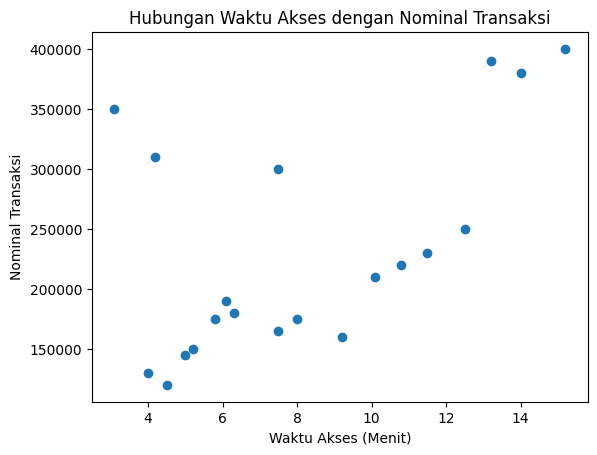

In [13]:
plt.scatter(
    df['Waktu_Akses_Menit'],
    df['Nominal_Transaksi']
)

plt.xlabel('Waktu Akses (Menit)')
plt.ylabel('Nominal Transaksi')
plt.title('Hubungan Waktu Akses dengan Nominal Transaksi')
plt.show()

In [ ]:
Kesimpulan 1 — Warna tombol

Berdasarkan Independent T-Test, diperoleh p-value 0,2025 > 0,05. Artinya, tidak terdapat perbedaan yang signifikan pada nominal transaksi antara tombol Biru dan Hijau. Walaupun rata-rata transaksi tombol Hijau lebih tinggi, perbedaan tersebut belum cukup kuat secara statistik.

Rekomendasi:
Perusahaan tidak perlu mengganti warna tombol hanya berdasarkan nominal transaksi dari dataset ini. Pengujian dapat dilanjutkan dengan jumlah sampel yang lebih besar atau menggunakan indikator lain seperti conversion rate.

In [ ]:
Kesimpulan 2 — Metode pembayaran

Hasil One-Way ANOVA menunjukkan p-value sangat kecil, yaitu sekitar 0,00000000309 < 0,05. Artinya, terdapat perbedaan yang signifikan pada rata-rata nominal transaksi berdasarkan metode pembayaran.

Rata-rata tertinggi terdapat pada:

Kartu Kredit = Rp355.000

Kemudian:

Transfer Bank = Rp207.857,14

dan:

E-Wallet = Rp149.285,71

Rekomendasi:

Manajemen dapat memberikan perhatian lebih pada pengguna Kartu Kredit karena kelompok ini memiliki rata-rata nominal transaksi paling tinggi pada dataset.

In [ ]:
Kesimpulan 3 — Waktu akses

Hasil korelasi Pearson memperoleh r = 0,5556 dengan p-value = 0,01098 < 0,05. Artinya, terdapat hubungan positif yang signifikan antara waktu akses dengan nominal transaksi.

Rekomendasi:
Perusahaan dapat mengoptimalkan pengalaman pengguna selama proses browsing, misalnya dengan memberikan rekomendasi produk yang relevan, informasi produk yang jelas, atau promo yang menarik agar pengguna tetap tertarik melakukan transaksi.

In [ ]:
Secara keseluruhan, hasil ini menjawab tujuan praktikum: menggunakan T-Test untuk A/B Testing, ANOVA untuk tiga kelompok metode pembayaran, dan korelasi Pearson untuk hubungan waktu akses dengan nominal transaksi, kemudian menerjemahkan hasil p-value menjadi keputusan bisnis.